# Lab 1: Telco Customer Churn Analysis

## Introduction

This lab explores customer churn in the Telco Customer Churn dataset.
The work includes loading and cleaning the data, then examining churn
across demographic groups, phone service, contracts, billing, and
payment methods.

## Load the Dataset

Read the CSV file into a pandas DataFrame for analysis.

In [1]:
import pandas as pd

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Inspect the Dataset

Display the first five records.

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Inspect the Dataset

Display the last five records.

In [3]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [4]:
#check dataset size
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 7,043
Columns: 21


## 4. Data Preprocessing

Churn is converted from Yes/No to 1/0. Data types are inspected, and
TotalCharges is converted to numeric. This reveals 11 missing values.
Removing the affected rows leaves 7,032 records with no missing values.

In [ ]:
#convert churn to numbers
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df["Churn"].value_counts().sort_index()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [7]:
#display current data types
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                 int64
dtype: object

In [ ]:
#correct TotalCharges and display updated types
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [ ]:
#display the columns containing missing values
missing_values = df.isna().sum()

missing_values[missing_values > 0]

TotalCharges    11
dtype: int64

In [11]:
#remove the affected rows and verify

rows_before = len(df)

df = df.dropna().copy()

print(f"Rows removed: {rows_before - len(df)}")
print(f"Remaining rows: {len(df):,}")
print(f"Remaining columns: {df.shape[1]}")
print(f"Remaining missing values: {df.isna().sum().sum()}")

Rows removed: 11
Remaining rows: 7,032
Remaining columns: 21
Remaining missing values: 0


## 5. Data Exploration

### Demographic Analysis

- Gender: Customer numbers are similar. Churn rates are also close:
  26.96% for females and 26.20% for males.
- Senior citizens: Churn is higher among senior citizens (41.68%)
  than non-senior citizens (23.65%).
- Partner: Customers without a partner have higher churn (32.98%)
  than those with a partner (19.72%).
- Dependents: Customers without dependents have higher churn (31.28%)
  than those with dependents (15.53%).

In [12]:
import matplotlib.pyplot as plt
from IPython.display import display

#### Gender and Churn

The dataset contains 3,483 female and 3,549 male customers, so the
gender distribution is nearly equal. Churn rates are also similar:
26.96% for females and 26.20% for males.

,Customers,Churned,Churn_rate_percent
gender,,,
Female,3483,939,26.96
Male,3549,930,26.20


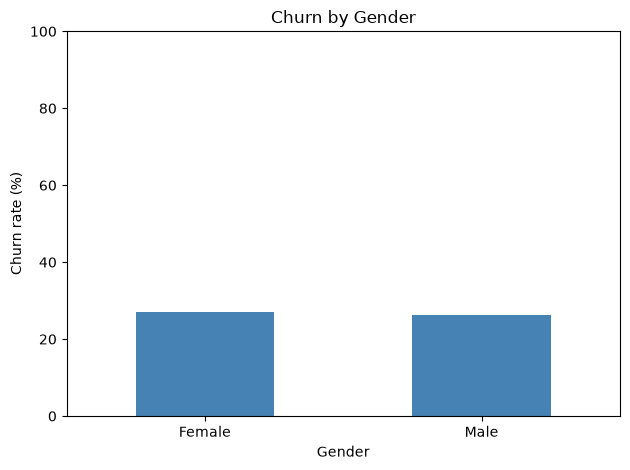

In [13]:
gender_summary = df.groupby("gender")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

gender_summary["Churn_rate_percent"] = (
    gender_summary["Churn_rate_percent"] * 100
).round(2)

display(gender_summary)

gender_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Gender",
    ylabel="Churn rate (%)",
    xlabel="Gender",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

#### Senior Citizen Status and Churn

Senior citizens have a higher churn rate (41.68%) than non-senior
citizens (23.65%). Although there are fewer senior customers,
a larger proportion of them left.

,Customers,Churned,Churn_rate_percent
SeniorCitizen,,,
Non-senior,5890,1393,23.65
Senior,1142,476,41.68


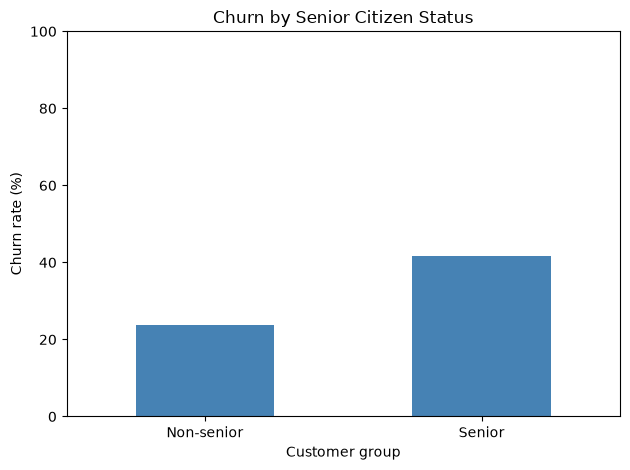

In [14]:
senior_summary = df.groupby("SeniorCitizen")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

senior_summary["Churn_rate_percent"] = (
    senior_summary["Churn_rate_percent"] * 100
).round(2)

senior_summary = senior_summary.rename(
    index={0: "Non-senior", 1: "Senior"}
)

display(senior_summary)

senior_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Senior Citizen Status",
    ylabel="Churn rate (%)",
    xlabel="Customer group",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

#### Partner Status and Churn

Customers without a partner have a churn rate of 32.98%, compared
with 19.72% for customers with a partner. Churn is therefore higher
among customers without a partner in this dataset.

,Customers,Churned,Churn_rate_percent
Partner,,,
No,3639,1200,32.98
Yes,3393,669,19.72


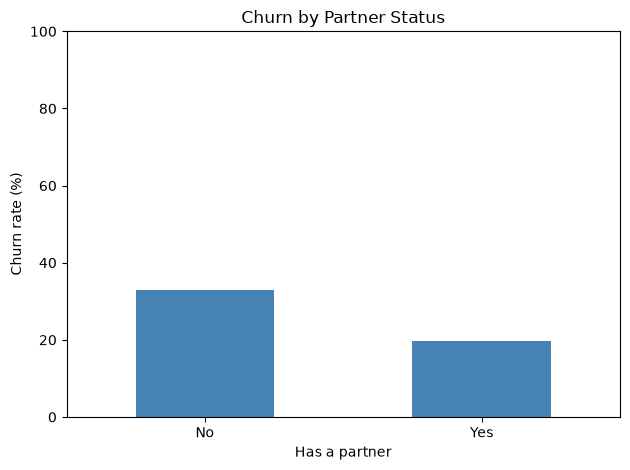

In [15]:
partner_summary = df.groupby("Partner")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

partner_summary["Churn_rate_percent"] = (
    partner_summary["Churn_rate_percent"] * 100
).round(2)

display(partner_summary)

partner_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Partner Status",
    ylabel="Churn rate (%)",
    xlabel="Has a partner",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

#### Dependents and Churn

Customers without dependents have a churn rate of 31.28%, compared
with 15.53% for customers with dependents. The churn rate is about
twice as high among customers without dependents.

,Customers,Churned,Churn_rate_percent
Dependents,,,
No,4933,1543,31.28
Yes,2099,326,15.53


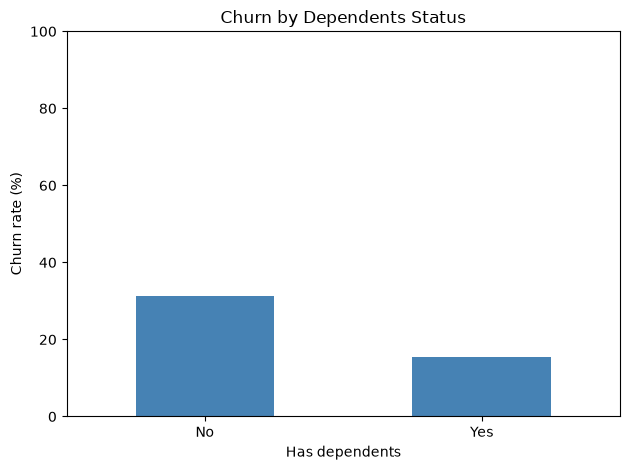

In [16]:
dependents_summary = df.groupby("Dependents")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

dependents_summary["Churn_rate_percent"] = (
    dependents_summary["Churn_rate_percent"] * 100
).round(2)

display(dependents_summary)

dependents_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Dependents Status",
    ylabel="Churn rate (%)",
    xlabel="Has dependents",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

### Service Analysis

#### Phone Service and Churn

Most customers have phone service. Their churn rate is 26.75%,
compared with 25.00% for customers without phone service.
The difference between the two groups is small.

,Customers,Churned,Churn_rate_percent
PhoneService,,,
No,680,170,25.00
Yes,6352,1699,26.75


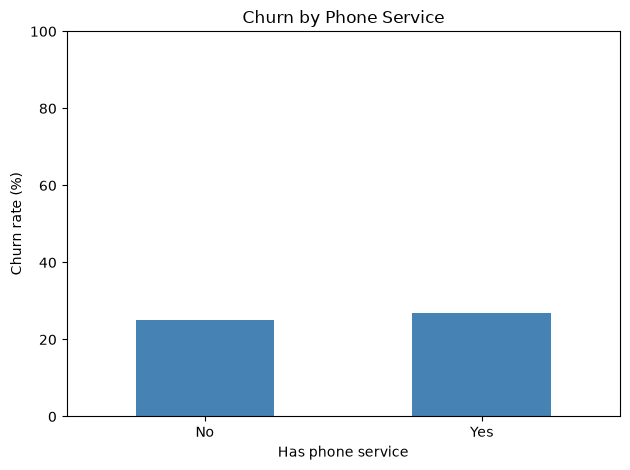

In [17]:
phone_summary = df.groupby("PhoneService")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

phone_summary["Churn_rate_percent"] = (
    phone_summary["Churn_rate_percent"] * 100
).round(2)

display(phone_summary)

phone_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Phone Service",
    xlabel="Has phone service",
    ylabel="Churn rate (%)",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

### Payments Analysis

#### Contract and Churn

Month-to-month customers have the highest churn rate (42.71%),
followed by one-year customers (11.28%) and two-year customers (2.85%).
Longer contracts are associated with lower churn in this dataset.

,Customers,Churned,Churn_rate_percent
Contract,,,
Month-to-month,3875,1655,42.71
One year,1472,166,11.28
Two year,1685,48,2.85


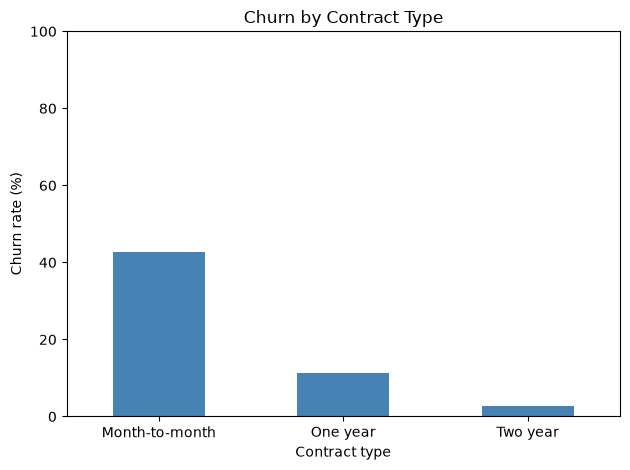

In [18]:
contract_summary = df.groupby("Contract")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

contract_summary["Churn_rate_percent"] = (
    contract_summary["Churn_rate_percent"] * 100
).round(2)

display(contract_summary)

contract_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Contract Type",
    xlabel="Contract type",
    ylabel="Churn rate (%)",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

#### Paperless Billing and Churn

Customers using paperless billing have a churn rate of 33.59%,
compared with 16.38% for customers without it.
Churn is about twice as high among paperless billing customers.

,Customers,Churned,Churn_rate_percent
PaperlessBilling,,,
No,2864,469,16.38
Yes,4168,1400,33.59


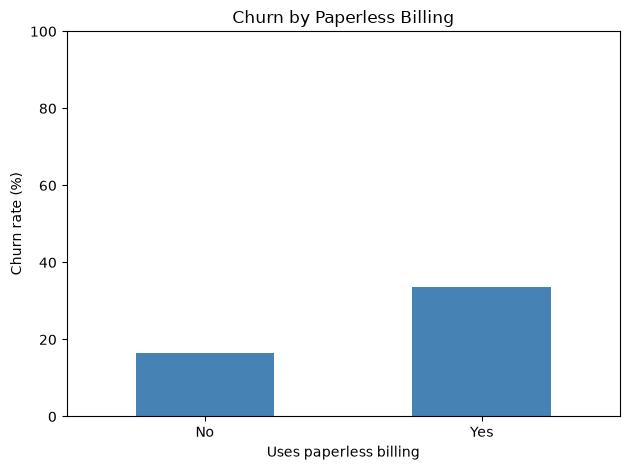

In [19]:
billing_summary = df.groupby("PaperlessBilling")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

billing_summary["Churn_rate_percent"] = (
    billing_summary["Churn_rate_percent"] * 100
).round(2)

display(billing_summary)

billing_summary["Churn_rate_percent"].plot(
    kind="bar",
    title="Churn by Paperless Billing",
    xlabel="Uses paperless billing",
    ylabel="Churn rate (%)",
    ylim=(0, 100),
    rot=0,
    color="steelblue"
)

plt.tight_layout()
plt.show()

#### Payment Method and Churn

Electronic check customers have the highest churn rate (45.29%).
The rates are 19.20% for mailed checks, 16.73% for automatic bank
transfers, and 15.25% for automatic credit card payments.
These differences show associations, not proof of causation.

,Customers,Churned,Churn_rate_percent
PaymentMethod,,,
Bank transfer (automatic),1542,258,16.73
Credit card (automatic),1521,232,15.25
Electronic check,2365,1071,45.29
Mailed check,1604,308,19.20


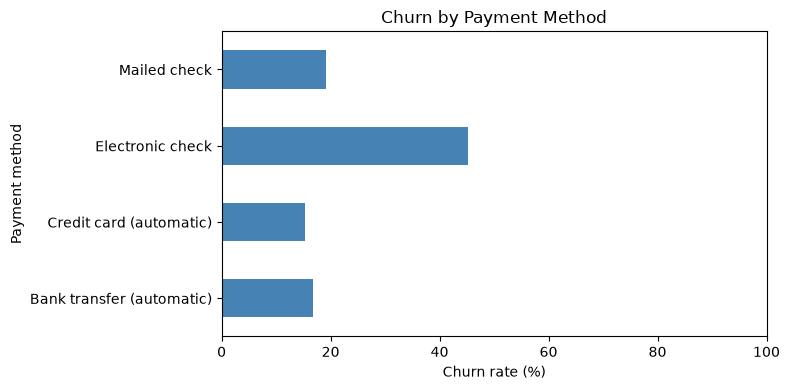

In [20]:
payment_summary = df.groupby("PaymentMethod")["Churn"].agg(
    Customers="count",
    Churned="sum",
    Churn_rate_percent="mean"
)

payment_summary["Churn_rate_percent"] = (
    payment_summary["Churn_rate_percent"] * 100
).round(2)

display(payment_summary)

payment_summary["Churn_rate_percent"].plot(
    kind="barh",
    title="Churn by Payment Method",
    xlabel="Churn rate (%)",
    ylabel="Payment method",
    xlim=(0, 100),
    figsize=(8, 4),
    color="steelblue"
)

plt.tight_layout()
plt.show()